# Multi-Objective Optimization with a Mechanistic Model

Most real optimization problems have more than one objective, and they pull
against each other: more yield costs more impurity, more throughput costs more
energy, a faster batch costs selectivity. There is then **no single best run**.
There is a *Pareto front* -- the set of operating points where you cannot
improve one objective without giving up some of another -- and choosing a point
on it is a judgement about value (what is a percent of purity worth?), not
something the data can decide for you.

What the data *can* do is tell you where the front is, as precisely as possible,
from as few experiments as possible. This notebook does that with
`model_based_optimize_round(..., objectives=...)`:

* **one mechanistic model, several responses.** The yield and the impurity
  come out of the same reaction network, so they share the same rate constants.
  They are fitted *jointly*, each weighted by its own measurement error -- an
  impurity measurement teaches you about the rate constants too.
* **model-based ParEGO** {cite:p}`Knowles2006`. Each recommended run draws a
  random weight vector, the *model's predictions* are scalarized with the
  augmented Chebyshev function, and expected improvement runs on that
  scalarized prediction with its linearized uncertainty. One weight vector per
  run spreads a batch along the trade-off.
* **a predicted front.** Because the model covers the whole design space, every
  round returns the trade-off curve the fitted model predicts, with standard
  errors -- including where no experiment has been run.

We compare it against the empirical version (`optimize_round(...,
objectives=...)`, ParEGO on a Gaussian process) on the same problem and budget.


In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt

import discopt.modeling as dm
from discopt.estimate import Experiment, ExperimentModel
from discopt.doe import model_based_optimize_round, optimize_round
from discopt.doe.workbook import InputSpec, Workbook


## 1. The problem: yield against impurity in a series reaction

A batch reaction makes the product $B$ from $A$, but $B$ degrades to an
impurity $C$:

$$A \xrightarrow{k_1} B \xrightarrow{k_2} C, \qquad
k_i(T) = k_{i,\mathrm{ref}} \exp\!\left[-\frac{E_i}{R}\left(\frac{1}{T} -
\frac{1}{T_\mathrm{ref}}\right)\right].$$

We control the temperature $T \in [310, 350]$ K and the batch time
$t \in [0.25, 4]$ h, and measure the yield of $B$ and the impurity $C$ (both as
fractions of the starting $A$). We want **high yield and low impurity**.

The degradation has the larger activation energy ($E_2 > E_1$), so heating
speeds up the impurity more than the product. That is what makes this a real
trade-off: the fastest way to more yield (heat) is also the fastest way to more
impurity. The "true" parameters below play the role of nature; the optimizer
never sees them.


In [2]:
R = 8.314e-3          # kJ/mol/K
T_REF = 330.0         # K
T_BOUNDS = (310.0, 350.0)
t_BOUNDS = (0.25, 4.0)
TRUE = {"k1": 1.0, "E1": 50.0, "k2": 0.08, "E2": 90.0}
SIGMA = {"yield_B": 0.01, "impurity_C": 0.002}   # measurement error (fractions)


def nature(T, t, theta=TRUE):
    """The real plant: yield of B and impurity C (noise-free)."""
    k1 = theta["k1"] * np.exp(-theta["E1"] / R * (1 / T - 1 / T_REF))
    k2 = theta["k2"] * np.exp(-theta["E2"] / R * (1 / T - 1 / T_REF))
    a = np.exp(-k1 * t)
    b = k1 / (k2 - k1) * (np.exp(-k1 * t) - np.exp(-k2 * t))
    return b, 1.0 - a - b


# The true Pareto front, on a dense grid -- for checking only.
TT, tt = np.meshgrid(np.linspace(*T_BOUNDS, 300), np.linspace(*t_BOUNDS, 300))
Y_grid, C_grid = nature(TT, tt)


def pareto_mask(F):
    """True where a row of F (every column larger-is-better) is non-dominated."""
    keep = np.ones(len(F), dtype=bool)
    for i in range(len(F)):
        if keep[i]:
            dominated = np.all(F >= F[i], axis=1) & np.any(F > F[i], axis=1)
            keep[i] = not dominated.any()
    return keep


grid = np.column_stack([Y_grid.ravel(), C_grid.ravel()])
true_front = grid[pareto_mask(grid * [1, -1])]
true_front = true_front[np.argsort(true_front[:, 0])]
print(f"best possible yield on the box: {Y_grid.max():.3f}")
print(f"true front spans yield {true_front[0, 0]:.2f}-{true_front[-1, 0]:.2f}, "
      f"impurity {100 * true_front[0, 1]:.2f}-{100 * true_front[-1, 1]:.1f} %")


best possible yield on the box: 0.836
true front spans yield 0.07-0.84, impurity 0.01-9.0 %


## 2. The model, with both responses

One `Experiment`, two responses. Both are expressions in the same four
parameters, and each has its own measurement error: impurity assays (HPLC area
percent at low levels) are five times more precise than the yield here.


In [3]:
class SeriesReaction(Experiment):
    def create_model(self, k1=0.5, E1=40.0, k2=0.05, E2=60.0):
        m = dm.Model("series")
        k1v = m.continuous("k1", lb=0.2, ub=5.0)
        E1v = m.continuous("E1", lb=10.0, ub=150.0)
        k2v = m.continuous("k2", lb=0.005, ub=0.15)
        E2v = m.continuous("E2", lb=10.0, ub=150.0)
        T = m.continuous("T", lb=T_BOUNDS[0], ub=T_BOUNDS[1])
        t = m.continuous("t", lb=t_BOUNDS[0], ub=t_BOUNDS[1])

        K1 = k1v * dm.exp(-E1v / R * (1 / T - 1 / T_REF))
        K2 = k2v * dm.exp(-E2v / R * (1 / T - 1 / T_REF))
        B = K1 / (K2 - K1) * (dm.exp(-K1 * t) - dm.exp(-K2 * t))
        C = 1 - dm.exp(-K1 * t) - B
        return ExperimentModel(
            model=m,
            unknown_parameters={"k1": k1v, "E1": E1v, "k2": k2v, "E2": E2v},
            design_inputs={"T": T, "t": t},
            responses={"yield_B": B, "impurity_C": C},
            measurement_error=SIGMA,
        )


experiment = SeriesReaction()
OBJECTIVES = {"yield_B": "maximize", "impurity_C": "minimize"}
GUESS = {"k1": 0.5, "E1": 40.0, "k2": 0.05, "E2": 60.0}   # deliberately off


## 3. A five-run seed

A $2^2$ factorial on (T, t) plus a centre point -- the kind of scouting runs a
chemist does anyway. The workbook's response column is the yield; the impurity
is an `extra_columns` entry filled in alongside it.


In [4]:
SEED_RUNS = [(312, 0.5), (348, 0.5), (312, 3.5), (348, 3.5), (330, 2.0)]


def new_campaign(path):
    if os.path.exists(path):
        os.remove(path)
    Workbook.create(
        path,
        template=None,
        template_args={},
        input_specs=[InputSpec("T", *T_BOUNDS), InputSpec("t", *t_BOUNDS)],
        criterion="model-based",
        measurement_error=SIGMA["yield_B"],
        seed=0,
        response_name="yield_B",
        module_callable=None,
        param_initial_guess=GUESS,
        extra_columns=["impurity_C"],
    )
    wb = Workbook.open(path)
    wb.append_runs(0, [{"T": T, "t": t} for T, t in SEED_RUNS])
    wb.save()


def run_pending(path, rng):
    """'Run' every pending experiment and record both measurements."""
    wb = Workbook.open(path)
    yields, impurities = {}, {}
    for r in wb.pending_runs():
        b, c = nature(r["T"], r["t"])
        yields[r["run_id"]] = float(b + SIGMA["yield_B"] * rng.normal())
        impurities[r["run_id"]] = {"impurity_C": float(c + SIGMA["impurity_C"] * rng.normal())}
    wb.record_responses(yields, extra=impurities)
    wb.save()


def measured(path):
    runs = Workbook.open(path).completed_runs()
    return np.array([[r["T"], r["t"], r["yield_B"], r["impurity_C"]] for r in runs])


PATH = "mo_model_based.xlsx"
new_campaign(PATH)
run_pending(PATH, np.random.default_rng(0))
for T, t, y, c in measured(PATH):
    print(f"T = {T:5.1f} K  t = {t:4.2f} h   yield = {y:.3f}   impurity = {100 * c:5.2f} %")


T = 312.0 K  t = 0.50 h   yield = 0.161   impurity =  0.02 %
T = 348.0 K  t = 0.50 h   yield = 0.641   impurity =  8.83 %
T = 312.0 K  t = 3.50 h   yield = 0.683   impurity =  1.83 %
T = 348.0 K  t = 3.50 h   yield = 0.274   impurity = 74.04 %
T = 330.0 K  t = 2.00 h   yield = 0.772   impurity =  8.30 %


## 4. One multi-objective round

The only change from single-objective model-based optimization is
`objectives=`: a mapping from response names to `"maximize"`/`"minimize"`.


In [5]:
result = model_based_optimize_round(
    PATH,
    experiment=experiment,
    initial_guess=GUESS,
    objectives=OBJECTIVES,
    batch_size=3,
    seed=0,
)
print("\n".join(result.log))
print()
for name, value in result.parameters.items():
    print(f"  {name:3s} = {value:8.4f} ± {result.parameter_se[name]:.4f}   (truth {TRUE[name]})")
print()
for w, d in zip(result.scalarization_weights, result.next_designs):
    print(f"  weights (yield, impurity) = ({w[0]:.2f}, {w[1]:.2f})  ->  T = {d['T']:.1f} K, t = {d['t']:.2f} h")


fit 4 parameter(s) jointly to 2 response(s) on 5 completed run(s)
objectives={'yield_B': 'maximize', 'impurity_C': 'minimize'}, acquisition=expected_improvement, batch_size=3
recommended runs [6, 7, 8]
3 measured run(s) on the Pareto front; 103 candidate(s) on the predicted front
fim_log_det=23.4849

  k1  =   0.9937 ± 0.0164   (truth 1.0)
  E1  =  50.6038 ± 0.9275   (truth 50.0)
  k2  =   0.0787 ± 0.0018   (truth 0.08)
  E2  =  90.9978 ± 1.2492   (truth 90.0)

  weights (yield, impurity) = (0.78, 0.22)  ->  T = 315.0 K, t = 3.95 h
  weights (yield, impurity) = (0.94, 0.06)  ->  T = 319.1 K, t = 3.96 h
  weights (yield, impurity) = (0.06, 0.94)  ->  T = 310.7 K, t = 3.23 h


Five runs were enough to pin down all four kinetic parameters, from a
starting guess that was off by a factor of two -- because ten measurements (two
per run) inform a model with four parameters, and the impurity measurements,
being precise, carry a lot of the information about $k_2$ and $E_2$.

Each of the three recommended runs comes from a different weight vector, so they
probe different parts of the trade-off. Now look at the front the model
predicts. `result.predicted_front` is a list of candidate designs that the
fitted model says are non-dominated, each with its predicted yield and impurity
and their standard errors.


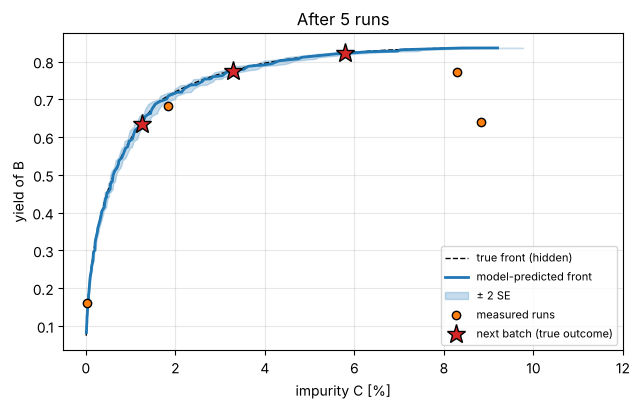

In [6]:
def plot_front(result, ax, label="model-predicted front"):
    pf = result.predicted_front
    y = np.array([p["yield_B"] for p in pf])
    c = np.array([p["impurity_C"] for p in pf])
    c_se = np.array([p["impurity_C_se"] for p in pf])
    ax.plot(100 * true_front[:, 1], true_front[:, 0], "k--", lw=1, label="true front (hidden)")
    ax.plot(100 * c, y, "C0-", lw=2, label=label)
    ax.fill_betweenx(y, 100 * (c - 2 * c_se), 100 * (c + 2 * c_se), color="C0", alpha=0.25,
                     label="± 2 SE")
    data = measured(result.workbook_path)
    ax.plot(100 * data[:, 3], data[:, 2], "o", color="C1", mec="k", label="measured runs")
    nxt = result.next_designs
    nb, nc = nature(np.array([d["T"] for d in nxt]), np.array([d["t"] for d in nxt]))
    ax.plot(100 * nc, nb, "*", ms=14, color="C3", mec="k", label="next batch (true outcome)")
    ax.set_xlabel("impurity C [%]")
    ax.set_ylabel("yield of B")
    ax.set_xlim(-0.5, 12)
    ax.legend(loc="lower right", fontsize=8)
    ax.grid(alpha=0.3)


fig, ax = plt.subplots(figsize=(6.5, 4.2))
plot_front(result, ax)
ax.set_title(f"After {result.n_completed} runs")
plt.tight_layout()
plt.show()


The predicted front lies on top of the true one along its whole length,
with tight uncertainty bands, after **five** experiments -- only one of which
(the cold, short scouting run) sits on the front at all. That is the dividend of a mechanistic model: it does not need data on
the front to know where the front is, only data that pins down the parameters.

The model also tells us *how* to move along the front. Plot the predicted-front
designs in the (T, t) plane:


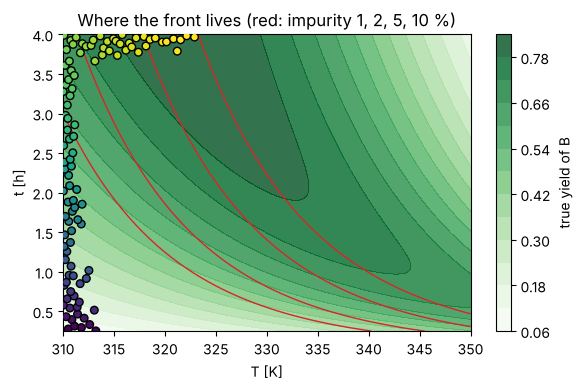

In [7]:
pf = result.predicted_front
fig, ax = plt.subplots(figsize=(6, 4))
cs = ax.contourf(TT, tt, Y_grid, levels=12, cmap="Greens", alpha=0.8)
ax.contour(TT, tt, 100 * C_grid, levels=[1, 2, 5, 10], colors="C3", linewidths=1)
sc = ax.scatter([p["T"] for p in pf], [p["t"] for p in pf], c=[p["yield_B"] for p in pf],
                cmap="viridis", edgecolor="k", s=30, zorder=3)
plt.colorbar(cs, ax=ax, label="true yield of B")
ax.set_xlabel("T [K]")
ax.set_ylabel("t [h]")
ax.set_title("Where the front lives (red: impurity 1, 2, 5, 10 %)")
plt.tight_layout()
plt.show()


The front is an L: **stay cold and extend the batch** until you hit the
4-hour limit, and only then start heating. Because degradation has the larger
activation energy, temperature is the expensive knob -- you reach for it only
when time has run out. That is the kind of operating rule a single-objective
optimum ("the max-yield point") would never show you, and it falls straight out
of the front.


## 5. Iterating

Running the recommended batches confirms the front (the new points land on it)
and tightens the parameters further. Four rounds of three:


 runs     SE(k1)     SE(E1)     SE(k2)     SE(E2)
    5     0.0164     0.9275     0.0018     1.2492
    8     0.0141     0.7621     0.0011     0.7710
   11     0.0132     0.7355     0.0009     0.6095
   14     0.0127     0.7207     0.0008     0.5309


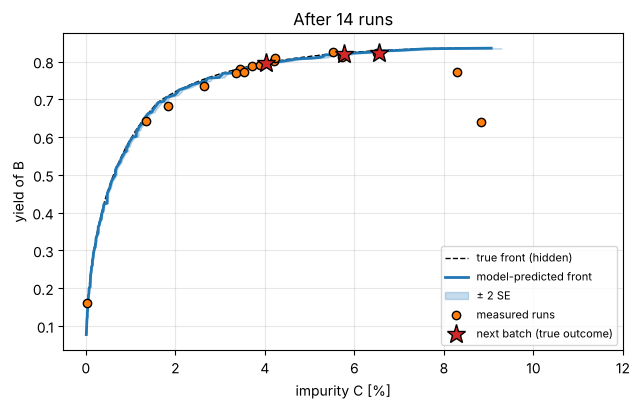

In [8]:
rng = np.random.default_rng(1)
history = [result]
run_pending(PATH, rng)
for k in range(1, 4):
    r = model_based_optimize_round(PATH, experiment=experiment, initial_guess=GUESS,
                                   objectives=OBJECTIVES, batch_size=3, seed=k)
    history.append(r)
    run_pending(PATH, rng)

print(f"{'runs':>5s} " + " ".join(f"{'SE(' + n + ')':>10s}" for n in TRUE))
for r in history:
    print(f"{r.n_completed:5d} " + " ".join(f"{r.parameter_se[n]:10.4f}" for n in TRUE))

fig, ax = plt.subplots(figsize=(6.5, 4.2))
plot_front(history[-1], ax)
ax.set_title(f"After {history[-1].n_completed} runs")
plt.tight_layout()
plt.show()


## 6. Against the empirical version

`optimize_round(..., objectives=...)` runs ParEGO on a Gaussian process: it
knows nothing about the chemistry and has to learn the shape of both responses
from the data. Give it the same seed runs and the same budget, and score each
method by the **hypervolume** of its front -- the area of objective space the
front dominates, relative to a reference point (zero yield, 10 % impurity),
divided by that of the true front. 1.0 means the true front.

For the GP the front is the set of measured runs, since that is all it can vouch
for. For the model we score the *predicted* front: we take its recommended
designs, run them in "nature", and compute the hypervolume of what actually
comes out. That is the honest test of a predicted front -- would it deliver if
you used it?


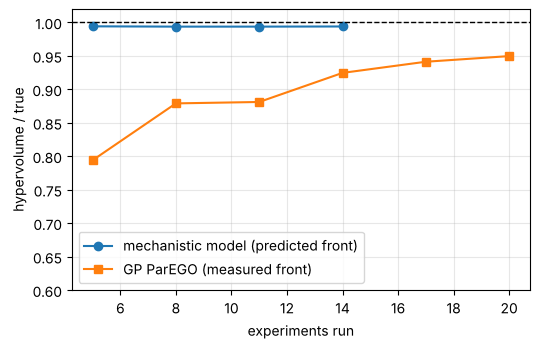

model,  5 runs: 0.994
model,  8 runs: 0.994
model, 11 runs: 0.994
model, 14 runs: 0.994
GP,     5 runs: 0.794
GP,     8 runs: 0.879
GP,    11 runs: 0.881
GP,    14 runs: 0.925
GP,    17 runs: 0.941
GP,    20 runs: 0.950


In [9]:
REF = np.array([0.0, 0.10])   # (yield, impurity) reference point


def hypervolume(Y):
    """Area dominated by (yield, impurity) points: maximize yield, minimize impurity."""
    P = np.column_stack([Y[:, 0] - REF[0], REF[1] - Y[:, 1]])
    P = P[(P[:, 0] > 0) & (P[:, 1] > 0)]
    if not len(P):
        return 0.0
    P = P[pareto_mask(P)]
    P = P[np.argsort(-P[:, 0])]
    area, prev = 0.0, 0.0
    for a, b in P:
        area += a * (b - prev)
        prev = b
    return area


HV_TRUE = hypervolume(true_front)


def predicted_front_hv(result):
    pf = result.predicted_front
    b, c = nature(np.array([p["T"] for p in pf]), np.array([p["t"] for p in pf]))
    return hypervolume(np.column_stack([b, c])) / HV_TRUE


model_curve = [(r.n_completed, predicted_front_hv(r)) for r in history]

GP_PATH = "mo_gp.xlsx"
new_campaign(GP_PATH)
rng = np.random.default_rng(0)
run_pending(GP_PATH, rng)
gp_curve = []
for k in range(5):
    data = measured(GP_PATH)
    gp_curve.append((len(data), hypervolume(data[:, 2:]) / HV_TRUE))
    optimize_round(GP_PATH, objectives=OBJECTIVES, batch_size=3, seed=k)
    run_pending(GP_PATH, rng)
data = measured(GP_PATH)
gp_curve.append((len(data), hypervolume(data[:, 2:]) / HV_TRUE))

fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.plot(*zip(*model_curve), "o-", label="mechanistic model (predicted front)")
ax.plot(*zip(*gp_curve), "s-", label="GP ParEGO (measured front)")
ax.axhline(1.0, color="k", ls="--", lw=1)
ax.set_xlabel("experiments run")
ax.set_ylabel("hypervolume / true")
ax.set_ylim(0.6, 1.02)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

for (n, h) in model_curve:
    print(f"model, {n:2d} runs: {h:.3f}")
for (n, h) in gp_curve:
    print(f"GP,    {n:2d} runs: {h:.3f}")


The model's front is essentially exact from the seed runs on; the GP
climbs towards it one batch at a time and is still short after twenty runs.
That gap is the value of knowing the mechanism. It cuts both ways: a model with
the wrong mechanism would give a confidently wrong front, which is why the
recommended batches keep *measuring* points on it -- if they stop landing on the
predicted curve, the model is wrong, and the GP version (or a better model) is
the fallback.


## 7. Using the front to make a decision

Suppose the specification is **impurity at most 1 %**. The front turns that
into a one-line lookup: the best yield the process can deliver within spec, with
an uncertainty, and the conditions that deliver it.


In [10]:
final = history[-1]
in_spec = [p for p in final.predicted_front if p["impurity_C"] + 2 * p["impurity_C_se"] <= 0.01]
best = max(in_spec, key=lambda p: p["yield_B"])
print(f"run at T = {best['T']:.1f} K, t = {best['t']:.2f} h")
print(f"predicted yield    {best['yield_B']:.3f} ± {best['yield_B_se']:.3f}")
print(f"predicted impurity {100 * best['impurity_C']:.2f} ± {100 * best['impurity_C_se']:.2f} %")

b, c = nature(best["T"], best["t"])
ok = C_grid <= 0.01
print(f"\nnature at that point: yield {b:.3f}, impurity {100 * c:.2f} %")
print(f"best in-spec yield anywhere on the box: {Y_grid[ok].max():.3f}")


run at T = 310.7 K, t = 2.72 h
predicted yield    0.575 ± 0.004
predicted impurity 0.94 ± 0.02 %

nature at that point: yield 0.575, impurity 0.94 %
best in-spec yield anywhere on the box: 0.593


We asked for a design whose impurity is within spec *with margin*
(prediction plus two standard errors), and the prediction matches what nature
delivers there to three decimals -- without a single experiment run at that
condition. It sits about two points of yield below the best in-spec yield the
process allows: part of that is the safety margin we asked for, part the
finite candidate pool the front is drawn from (pass a larger `n_candidates` to
draw it finer).

## Summary

* `model_based_optimize_round(objectives={...})` optimizes several responses of
  one mechanistic model, fitted **jointly** with per-response measurement errors
  (`measurement_noise_override` takes a per-response mapping too).
* Each run in a batch gets its own random weight vector (ParEGO), so a batch
  spreads along the trade-off; `scalarization_weights` records them.
* `pareto_front` holds the measured non-dominated runs; `predicted_front` the
  model's whole trade-off curve with standard errors -- usually the more useful
  of the two, as far as the model can be trusted.
* With a trustworthy mechanism, the front can be accurate long before any run
  sits on it. Without one, use `optimize_round(objectives=...)` instead.

For the other kind of multi-objective design problem -- *information* traded
against cost, duration or production -- see the next notebook,
[Trade-offs in optimal design](design-tradeoffs.ipynb).
